In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.taxi_lts.validate_lts import run_validation

PROJECT_ROOT = Path.cwd()
pd.set_option("display.max_columns", 50)

/Users/ak007/Projects/Regression_Techniques_Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
validation = pd.Series(run_validation(), name="Value")
display(validation.to_frame())

,Value
n_observations,1000.000000
n_predictors,3.000000
n_contaminated,100.000000
contamination_added,50.000000
alpha,0.750000
h,750.000000
n_initial_subsets,500.000000
true_intercept,5.000000
ols_intercept,9.981014
raw_lts_intercept,4.992733


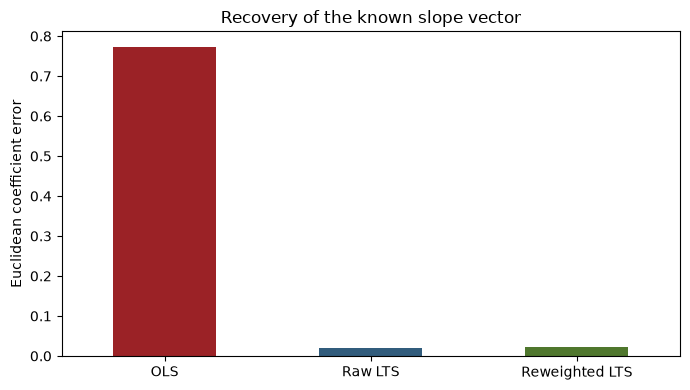

Detection recall: 100.0%
Detection precision: 86.2%


In [3]:
errors = validation[[
    "ols_coefficient_l2_error",
    "raw_lts_coefficient_l2_error",
    "reweighted_lts_coefficient_l2_error",
]].rename(index={
    "ols_coefficient_l2_error": "OLS",
    "raw_lts_coefficient_l2_error": "Raw LTS",
    "reweighted_lts_coefficient_l2_error": "Reweighted LTS",
})

ax = errors.plot.bar(figsize=(7, 4), color=["#9B2226", "#315C7C", "#4F772D"], legend=False)
ax.set_ylabel("Euclidean coefficient error")
ax.set_title("Recovery of the known slope vector")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(f"Detection recall: {validation['detection_recall']:.1%}")
print(f"Detection precision: {validation['detection_precision']:.1%}")

In [4]:
benchmark = pd.read_csv(PROJECT_ROOT / "outputs/tables/lts_scalability_benchmark.csv")
benchmark_view = benchmark[[
    "sample_size", "alpha", "h", "n_initial_subsets", "elapsed_seconds",
    "fit_peak_increase_mib", "reweighted_observations", "zero_weight_observations",
    "reweighted_fraction", "sample_source_id_sha256",
]].copy()
display(benchmark_view.style.format({
    "elapsed_seconds": "{:.2f}",
    "fit_peak_increase_mib": "{:.1f}",
    "reweighted_fraction": "{:.2%}",
}))

assert (benchmark["h"] == (0.75 * benchmark["sample_size"]).astype(int)).all()
assert benchmark["n_initial_subsets"].eq(500).all()
print("Benchmark configuration checks passed.")

,sample_size,alpha,h,n_initial_subsets,elapsed_seconds,fit_peak_increase_mib,reweighted_observations,zero_weight_observations,reweighted_fraction,sample_source_id_sha256
0,10000,0.750000,7500,500,1.40,40.6,8363,1637,83.63%,d921985d2b526b51a9b43a02847f0658fc0185e8a8a47cd061d518421e1e74a0
1,25000,0.750000,18750,500,3.35,113.0,20904,4096,83.62%,443b19a2dd34235711fe7a2bfca4c3e8cb632282481cbbd851ced19b6f643ca2
2,50000,0.750000,37500,500,7.18,213.2,41924,8076,83.85%,bbb8982488eb73d9bc8637ae27735972c71f35be2e7d6503ca5ea6ea9d0068f8


Benchmark configuration checks passed.


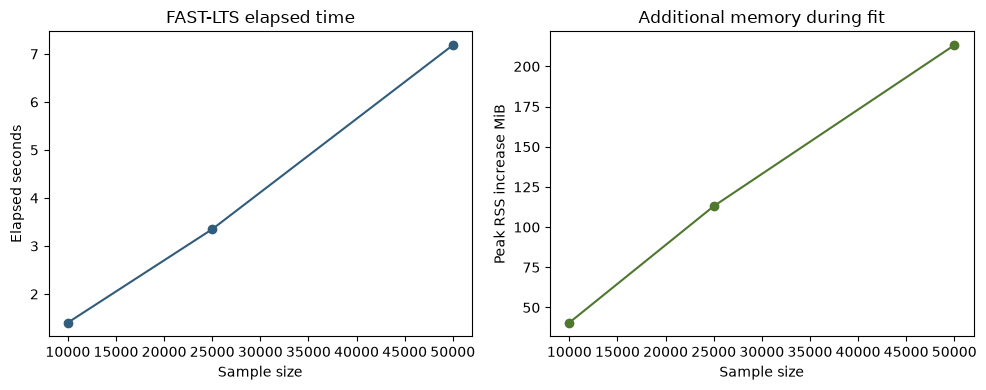

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(benchmark["sample_size"], benchmark["elapsed_seconds"], marker="o", color="#315C7C")
axes[0].set(xlabel="Sample size", ylabel="Elapsed seconds", title="FAST-LTS elapsed time")
axes[1].plot(benchmark["sample_size"], benchmark["fit_peak_increase_mib"], marker="o", color="#4F772D")
axes[1].set(xlabel="Sample size", ylabel="Peak RSS increase MiB", title="Additional memory during fit")
plt.tight_layout()
plt.show()